In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
amazon_original_df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
amazon_original_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
amazon_original_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
#Clean look for empty lines
amazon_original_df.isna().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

In [6]:
amazondf = amazon_original_df.copy()
amazondf.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [7]:
list(set(amazondf.dtypes.tolist()))

[dtype('float64'), dtype('bool'), dtype('int64'), dtype('O')]

In [8]:
amazondf.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [9]:
amazondf.select_dtypes("number").nunique().sort_values(ascending=False)


uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [10]:
top5 = amazondf["category"].value_counts().head(5).index

In [11]:
frequency_table = amazondf['category'].value_counts()

proportion_table = amazondf['category'].value_counts(normalize=True)

frequency_table, proportion_table

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Alexa Built-In Devices                       107
 Motorbike Chassis                            107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Alexa Built-In Devices                    0.000044
 Motorbike Chassis       

In [12]:
frequency_table.head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [13]:
top_5 = frequency_table.iloc[:5]

C:\Users\jejoc\AppData\Local\Temp\ipykernel_37640\277525951.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_5.index, y=top_5, palette="Set3");


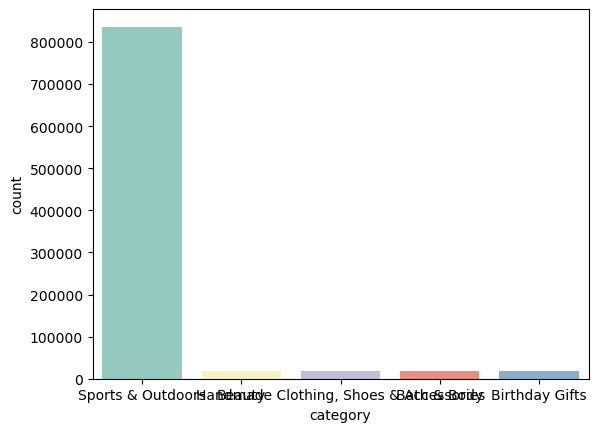

In [14]:
sns.barplot(x=top_5.index, y=top_5, palette="Set3");


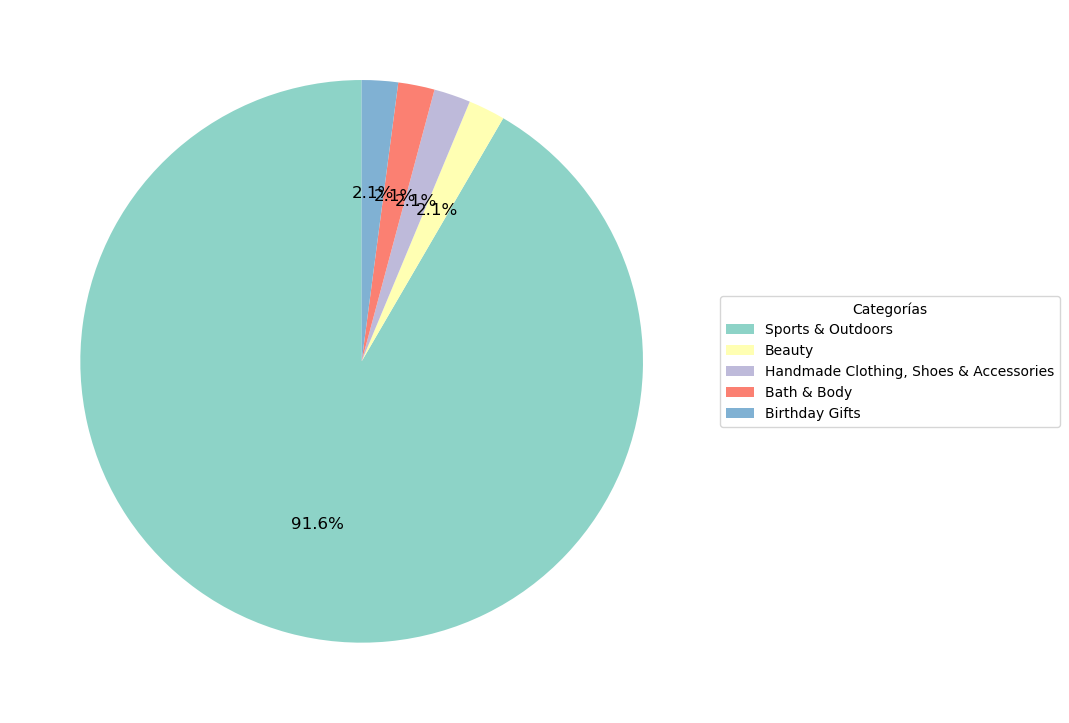

In [15]:
plt.figure(figsize=(10, 8))
 
 
top_5.plot.pie(
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3"),
    labels=None,
    textprops={'fontsize': 12}
)
 
plt.legend(
    labels=top_5.index,
    title='Categorías',
    bbox_to_anchor=(1, 0.5),
    loc='center left'
)
 
plt.ylabel('')
plt.tight_layout()
plt.show()

## PART 2

In [30]:
amazondf["price"] = pd.to_numeric(
    amazondf["price"],
    errors="coerce"
)

In [31]:
#Calculate the mean, median, and mode for the price of products.
amz_mean = amazondf["price"].mean()
amz_median = amazondf["price"].median()
amz_mode = amazondf["price"].mode()

print ("mean = ", amz_mean, 
       ", median  =", amz_median , 
       ", mode= ", amz_mode)

mean =  89.24380943923661 , median  = 19.09 , mode=  0    9.99
Name: price, dtype: float64


In [32]:
# The avarage price is 89,99 and the most common price 19,09. T

In [33]:
amz_std = amazondf["price"].std(ddof=0)
amz_var = amazondf["price"].var(ddof=0)
amz_max = amazondf["price"].max()
amz_min = amazondf["price"].min()
range_amz = amz_max - amz_min
quantiles_price = amazondf['price'].quantile([0.25, 0.5, 0.75])

print(f"""
Std: {amz_std}
Variance: {amz_var}
Range: {range_amz}
Quantile: {quantiles_price}
""")


Std: 345.60879103783964
Variance: 119445.43644263712
Range: 100000.0
Quantile: 0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64



In [34]:
#The 75% of the products are under 45.99$ 
#And the last quantile is between 45.99$ and 100.000$
#There is a big variations of prices from the mean , meanwhile the standard deviation is low coparing to the range so the values are closer to the mean and are less products with high prices probebly because most of the product are from the same category

<Axes: xlabel='price', ylabel='Count'>

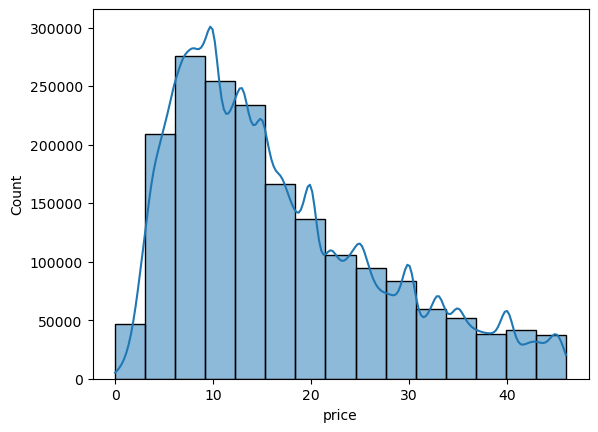

In [39]:
price_filter = amazondf[amazondf["price"] <= 45.99]

sns.histplot(price_filter["price"], bins=15, kde=True)

<Axes: ylabel='price'>

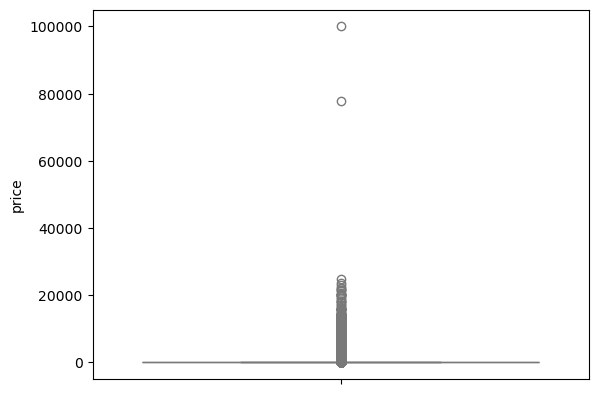

In [40]:
sns.boxplot(data = amazondf['price'], color="lightblue")

### PART 3

In [41]:
#Calculate the mean, median, and mode for the price of products.
rating_mean = amazondf["stars"].mean()
rating_median = amazondf["stars"].median()
rating_mode = amazondf["stars"].mode()

print ("mean = ", rating_mean, 
       ", median  =", rating_median , 
       ", mode= ", rating_mode)

mean =  2.152836472966066 , median  = 0.0 , mode=  0    0.0
Name: stars, dtype: float64


In [ ]:
#Generally customers don't rate the prooducts

In [42]:
rating_std = amazondf["stars"].std(ddof=0)
rating_var = amazondf["stars"].var(ddof=0)
rating_max = amazondf["stars"].max()
rating_min = amazondf["stars"].min()
rating_range_amz = rating_max - rating_min
quantiles_rating = amazondf['stars'].quantile([0.25, 0.5, 0.75])

print(f"""
Std: {rating_std}
Variance: {rating_var}
Range: {rating_range_amz}
Quantile: {quantiles_rating}
""")


Std: 2.194864929409915
Variance: 4.8174320583535915
Range: 5.0
Quantile: 0.25    0.0
0.50    0.0
0.75    4.4
Name: stars, dtype: float64



In [ ]:
#Best qualifications are near de 25% of the  ratings, another 25% between 0 and 4,4 stars. And more than 50% have no review or are 0 stars.

In [45]:
skewness_rating = amazondf['stars'].skew()
kurtosis_rating = amazondf['stars'].kurtosis()

skewness_rating, kurtosis_rating

(np.float64(0.08120735761080881), np.float64(-1.9260061280432994))

In [ ]:
# The rating distribution is almost simetric understanding that raitings trend to be high and the negative kutosis makes us undertan that there distribution is plane also there are no many values to compare

<Axes: xlabel='stars', ylabel='Count'>

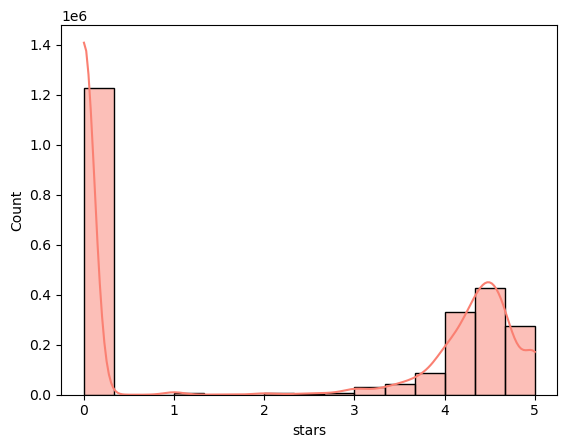

In [46]:
sns.histplot(amazondf['stars'], kde=True, bins=15, color="salmon")

<Axes: xlabel='stars', ylabel='Count'>

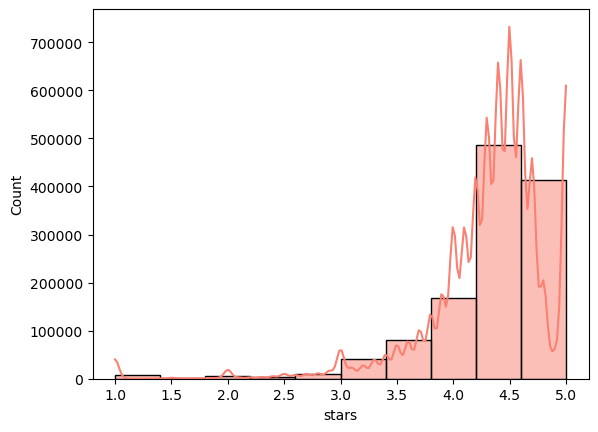

In [49]:
sns.histplot(
    amazondf[amazondf["stars"] > 0]["stars"],
    bins=10,
    kde=True,
    color="salmon"
)

In [ ]:
#the distribution is centren between 4 and 4.5 stars with not much neggative reviews